# 2º Trabalho de Fundamentos de IA — Etapa 1: Aprendizado Simbólico (Árvore de Decisão)
**Domínio:** Educação (SAEB + Censo 2010) · **IComp/UFAM** · Prof. Edjard Mota

**Pergunta prática:** *dado um município, sua dependência administrativa e localização, o desempenho médio em Matemática do Ensino Médio no SAEB melhorou de 2021 para 2023?*

Este notebook cobre as 7 tarefas da Etapa 1 do enunciado:

1. Variável-alvo binária → `ALVO_MELHORA`
2. 4–6 atributos interpretáveis
3. Entropia e ganho de informação (3 primeiros níveis)
4. `LEARN-DECISION-TREE` implementado do zero
5. Comparação com `DecisionTreeClassifier` (scikit-learn)
6. Validação cruzada 5-fold
7. Monotonicidade (demonstração empírica)

> **Premissa metodológica (do relatório):** 2021 = período *anterior* ao Novo Ensino Médio e 2023 = período *posterior*. É uma premissa do estudo, não uma confirmação das datas reais de implementação em cada município. O alvo mede **associação**, não efeito causal.

## 0. Configuração

In [ ]:
# Instala o pyxlsb (necessário para ler o .xlsb do SAEB 2023) se ainda não estiver disponível — útil no Colab
import importlib.util, subprocess, sys
if importlib.util.find_spec('pyxlsb') is None:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', 'pyxlsb'])

In [ ]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from collections import Counter

SEED = 42
np.random.seed(SEED)
pd.set_option('display.width', 160, 'display.max_columns', 30)

# Procura os arquivos de dados em alguns lugares comuns
for d in [Path('dados'), Path('.'), Path('/content'), Path('/content/dados'), Path('/mnt/user-data/uploads')]:
    if (d / 'saeb_2021_brasil_estados_municipios.xlsx').exists():
        DATA_DIR = d; break
else:
    DATA_DIR = None   # sem arquivos brutos: usaremos o conjunto embutido no notebook
print('Pasta dos dados brutos:', DATA_DIR.resolve() if DATA_DIR else 'não encontrada (será usado o conjunto embutido)')

Pasta dos dados brutos: não encontrada (será usado o conjunto embutido)


## 1. Carga dos dados
- **SAEB 2021** (`.xlsx`, aba *Municípios*) e **SAEB 2023** (`.xlsb`, aba *Municípios*, requer `pip install pyxlsb`). A linha 2 de cada aba é uma descrição das colunas e é descartada.
- **Censo/Atlas 2010**: `IDHM_R` (IDH-M renda) por município, chave pelo código IBGE de 7 dígitos (`Codmun7`).
- Para o Ensino Médio usamos `MEDIA_12_MT` (média de Matemática da última série do EM).

In [ ]:
# Verificação opcional dos arquivos brutos (upload truncado/corrompido é a causa mais comum de BadZipFile).
# Se algo estiver errado, o notebook NÃO para: cai automaticamente no conjunto embutido logo abaixo.
import zipfile
ESPERADO = {'saeb_2021_brasil_estados_municipios.xlsx': 21638585,
            'Resultados_Saeb_2023_Brasil_Estados_Municipios.xlsb': 8372556,
            'censo_total_1991_2010_MUN_91-00-10_.csv': 1397389}
if DATA_DIR is not None:
    for nome, tam in ESPERADO.items():
        p = DATA_DIR / nome
        if not p.exists(): print(f'FALTANDO: {nome}'); continue
        ok_zip = zipfile.is_zipfile(p) if nome.endswith(('.xlsx', '.xlsb')) else True
        print(f'{nome:<55} {p.stat().st_size:>12,} bytes (esperado {tam:,}) zip_ok={ok_zip}')

import io, gzip, base64

# Conjunto já filtrado e cruzado (SAEB 2021 + SAEB 2023 + IDHM_R do Censo 2010), embutido para dispensar uploads.
EMBUTIDO = "..."

def le_brutos():
    s21 = pd.read_excel(DATA_DIR/'saeb_2021_brasil_estados_municipios.xlsx', sheet_name='Municípios', skiprows=[1])
    s23 = pd.read_excel(DATA_DIR/'Resultados_Saeb_2023_Brasil_Estados_Municipios.xlsb', sheet_name='Municípios',
                        engine='pyxlsb', skiprows=[1])
    censo = pd.read_csv(DATA_DIR/'censo_total_1991_2010_MUN_91-00-10_.csv', sep=';', encoding='latin1', decimal=',')
    return s21, s23, censo[censo.ANO == 2010][['Codmun7', 'IDHM_R']]

try:
    if DATA_DIR is None: raise FileNotFoundError('arquivos brutos ausentes')
    s21, s23, censo10 = le_brutos(); FONTE = 'brutos'
    print('SAEB 2021:', s21.shape, '| SAEB 2023:', s23.shape, '| Censo 2010:', censo10.shape)
except Exception as e:   # BadZipFile (upload corrompido), arquivo ausente, pyxlsb ausente...
    FONTE = 'embutido'
    print(f'Não foi possível ler os arquivos brutos ({type(e).__name__}: {e}).')
    print('→ Usando o conjunto embutido no notebook (mesmo filtro e mesmo cruzamento descritos abaixo).')
print('Fonte dos dados:', FONTE)

Não foi possível ler os arquivos brutos (FileNotFoundError: arquivos brutos ausentes).
→ Usando o conjunto embutido no notebook (mesmo filtro e mesmo cruzamento descritos abaixo).
Fonte dos dados: embutido


## 2. Construção do conjunto de dados

### ⚠️ Decisão importante: linhas sobrepostas
As abas do SAEB trazem, para cada município, **linhas agregadas e sobrepostas**: `Total - Federal, Estadual, Municipal e Privada`, `Total - Estadual e Municipal`, localização `Total`, etc. Se usarmos todas, o mesmo município aparece várias vezes com valores quase idênticos, o que (i) infla artificialmente o conjunto e (ii) causa **vazamento** na validação cruzada (cópias quase idênticas caem em treino e teste).

Por isso a unidade de análise é **município × dependência × localização**, usando apenas categorias **mutuamente exclusivas**:
`DEPENDENCIA_ADM ∈ {Estadual, Federal, Municipal}` e `LOCALIZACAO ∈ {Urbana, Rural}`.

### Faixas (discretização com cortes fixos, sem olhar o alvo)
- `FAIXA_MEDIA_2021`: cortes em 250, 265 e 280 pontos (≈ quartis da distribuição de 2021).
- `FAIXA_IDHM_R`: faixas oficiais do IDHM (muito baixo < 0,5; baixo; médio; alto; muito alto ≥ 0,8).

In [ ]:
KEYS = ['CO_UF', 'CO_MUNICIPIO', 'DEPENDENCIA_ADM', 'LOCALIZACAO']
DEPS, LOCS = ['Estadual', 'Federal', 'Municipal'], ['Urbana', 'Rural']

def prepara(df):
    df = df[df.DEPENDENCIA_ADM.isin(DEPS) & df.LOCALIZACAO.isin(LOCS)]
    return df[KEYS + ['MEDIA_12_MT']].dropna()

if FONTE == 'brutos':
    a, b = prepara(s21), prepara(s23)
    df = a.merge(b, on=KEYS, suffixes=('_2021', '_2023'))
    df = df.merge(censo10, left_on='CO_MUNICIPIO', right_on='Codmun7', how='left').drop(columns='Codmun7')
    print(f'2021: {len(a)} | 2023: {len(b)} | pareados: {len(df)} | municípios distintos: {df.CO_MUNICIPIO.nunique()}')
    print('Sem IDHM_R (descartados):', df.IDHM_R.isna().sum())
    df = df.dropna(subset=['IDHM_R']).reset_index(drop=True)
else:
    df = pd.read_csv(io.StringIO(gzip.decompress(base64.b64decode(EMBUTIDO)).decode()))
    print(f'Conjunto embutido: {len(df)} linhas | municípios distintos: {df.CO_MUNICIPIO.nunique()}')

# --- variável-alvo ---
df['ALVO_MELHORA'] = (df.MEDIA_12_MT_2023 > df.MEDIA_12_MT_2021).astype(int)
# --- faixas ---
df['FAIXA_MEDIA_2021'] = pd.cut(df.MEDIA_12_MT_2021, [0, 250, 265, 280, 1000], right=False,
                                labels=['<250', '250-265', '265-280', '>=280']).astype(str)
df['FAIXA_IDHM_R'] = pd.cut(df.IDHM_R, [0, .5, .6, .7, .8, 2], right=False,
                            labels=['muito baixo', 'baixo', 'medio', 'alto', 'muito alto']).astype(str)
df['CO_UF'] = df.CO_UF.astype(str)

ATTRS = ['CO_UF', 'DEPENDENCIA_ADM', 'LOCALIZACAO', 'FAIXA_MEDIA_2021', 'FAIXA_IDHM_R']
TARGET = 'ALVO_MELHORA'
groups = df.CO_MUNICIPIO.values
X, y = df[ATTRS], df[TARGET].values
print(f'\nConjunto final: {len(df)} exemplos | proporção de melhora (classe 1): {y.mean():.3f}')
df[ATTRS + [TARGET]].head()

Conjunto embutido: 3519 linhas | municípios distintos: 3100

Conjunto final: 3519 exemplos | proporção de melhora (classe 1): 0.631


,CO_UF,DEPENDENCIA_ADM,LOCALIZACAO,FAIXA_MEDIA_2021,FAIXA_IDHM_R,ALVO_MELHORA
0,11,Estadual,Urbana,250-265,medio,1
1,11,Estadual,Urbana,265-280,alto,1
2,11,Estadual,Urbana,265-280,alto,0
3,11,Estadual,Urbana,265-280,medio,1
4,11,Estadual,Rural,>=280,medio,0


### 2.1 Exploração rápida: taxa de melhora por atributo

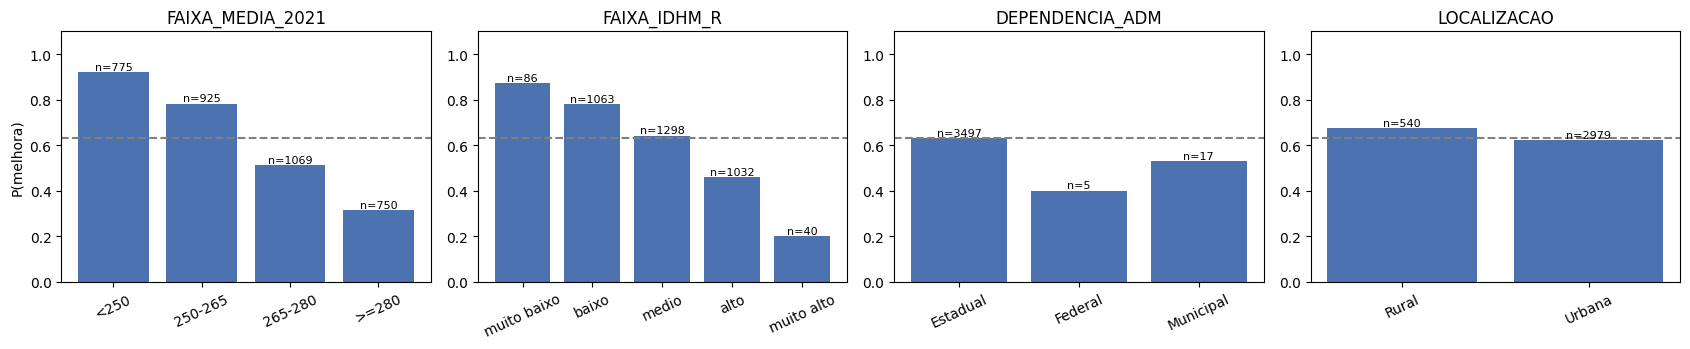

In [ ]:
fig, axs = plt.subplots(1, 4, figsize=(17, 3.6))
for ax, col in zip(axs, ['FAIXA_MEDIA_2021', 'FAIXA_IDHM_R', 'DEPENDENCIA_ADM', 'LOCALIZACAO']):
    order = {'FAIXA_MEDIA_2021': ['<250','250-265','265-280','>=280'],
             'FAIXA_IDHM_R': ['muito baixo','baixo','medio','alto','muito alto']}.get(col)
    t = df.groupby(col)[TARGET].agg(['mean', 'size'])
    if order: t = t.reindex(order)
    ax.bar(t.index, t['mean'], color='#4c72b0'); ax.axhline(y.mean(), ls='--', c='gray')
    for i, (m, n) in enumerate(zip(t['mean'], t['size'])): ax.text(i, m + .01, f'n={n}', ha='center', fontsize=8)
    ax.set_title(col); ax.set_ylim(0, 1.1); ax.tick_params(axis='x', rotation=25)
axs[0].set_ylabel('P(melhora)'); plt.tight_layout(); plt.show()

**Leitura:** a taxa de melhora cai de forma muito nítida com a faixa inicial. Municípios que começaram mal têm muito mais chance de "melhorar" — isso é em parte **regressão à média** (quem está muito abaixo tende a subir, quem está muito acima tende a descer, mesmo sem nenhuma intervenção). Esse efeito deve ser lembrado ao interpretar qualquer regra da árvore como efeito do Novo Ensino Médio.

## 3. Entropia e ganho de informação (cálculo explícito)

$$H(S)=-\sum_i p_i\log_2 p_i \qquad IG(S,A)=H(S)-\sum_v \frac{|S_v|}{|S|}H(S_v)$$

In [ ]:
def entropia(y):
    y = np.asarray(y)
    if len(y) == 0: return 0.0
    p = np.bincount(y, minlength=2) / len(y)
    p = p[p > 0]
    return float(-(p * np.log2(p)).sum())

def ganho(df_, attr):
    H_pai = entropia(df_[TARGET]); n = len(df_)
    H_filhos = sum(len(g) / n * entropia(g[TARGET]) for _, g in df_.groupby(attr))
    return H_pai - H_filhos

def detalhe_no_raiz(df_, attr):
    # mostra a substituição numérica na fórmula para um atributo
    n = len(df_); print(f'Atributo {attr}: H(S) = {entropia(df_[TARGET]):.4f}  (n={n})')
    soma = 0
    for v, g in df_.groupby(attr):
        h = entropia(g[TARGET]); soma += len(g) / n * h
        print(f'   v={v:<12} |S_v|={len(g):>5}  P(1)={g[TARGET].mean():.3f}  H(S_v)={h:.4f}  peso={len(g)/n:.3f}')
    print(f'   Σ peso·H = {soma:.4f}  →  IG = {entropia(df_[TARGET]) - soma:.4f}\n')

print(f'H(S) na raiz = {entropia(y):.4f} bits  (classe 1: {y.mean():.3f})\n')
gains_root = pd.Series({a_: ganho(df, a_) for a_ in ATTRS}).sort_values(ascending=False)
print(gains_root.round(4).to_string())
print()
detalhe_no_raiz(df, gains_root.index[0])
detalhe_no_raiz(df, gains_root.index[1])

H(S) na raiz = 0.9498 bits  (classe 1: 0.631)

FAIXA_MEDIA_2021    0.1686
CO_UF               0.1003
FAIXA_IDHM_R        0.0607
LOCALIZACAO         0.0011
DEPENDENCIA_ADM     0.0004

Atributo FAIXA_MEDIA_2021: H(S) = 0.9498  (n=3519)
   v=250-265      |S_v|=  925  P(1)=0.783  H(S_v)=0.7552  peso=0.263
   v=265-280      |S_v|= 1069  P(1)=0.512  H(S_v)=0.9996  peso=0.304
   v=<250         |S_v|=  775  P(1)=0.921  H(S_v)=0.3976  peso=0.220
   v=>=280        |S_v|=  750  P(1)=0.315  H(S_v)=0.8985  peso=0.213
   Σ peso·H = 0.7812  →  IG = 0.1686

Atributo CO_UF: H(S) = 0.9498  (n=3519)
   v=11           |S_v|=   29  P(1)=0.483  H(S_v)=0.9991  peso=0.008
   v=12           |S_v|=   10  P(1)=0.600  H(S_v)=0.9710  peso=0.003
   v=13           |S_v|=   72  P(1)=0.903  H(S_v)=0.4601  peso=0.020
   v=14           |S_v|=    2  P(1)=0.500  H(S_v)=1.0000  peso=0.001
   v=15           |S_v|=   72  P(1)=1.000  H(S_v)=-0.0000  peso=0.020
   v=16           |S_v|=    5  P(1)=0.600  H(S_v)=0.9710  peso=0.0

### 3.1 Os três primeiros níveis (raiz, nível 1, nível 2)
Para cada nó, mostramos o ganho de todos os atributos disponíveis e o atributo escolhido (maior ganho). Pelo pseudocódigo ID3, um atributo usado num ramo não é reutilizado abaixo dele.

In [ ]:
def mostra_niveis(df_, attrs, nivel=0, max_nivel=3, rotulo='raiz', min_n=40):
    if nivel >= max_nivel or len(df_) < (min_n if nivel >= 2 else 1) or df_[TARGET].nunique() == 1 or not attrs: return
    g = pd.Series({a_: ganho(df_, a_) for a_ in attrs}).sort_values(ascending=False)
    best = g.index[0]
    ind = '    ' * nivel
    resto = ', '.join(f'{k}={v:.3f}' for k, v in g.iloc[1:].items())
    print(f'{ind}[nível {nivel}] {rotulo}: n={len(df_)}, P(1)={df_[TARGET].mean():.2f}, H={entropia(df_[TARGET]):.3f}'
          f' → divide por {best} (IG={g.iloc[0]:.3f}) | demais: {resto}')
    for v, sub in df_.groupby(best):
        mostra_niveis(sub, [a_ for a_ in attrs if a_ != best], nivel + 1, max_nivel, f'{best}={v}')

mostra_niveis(df, ATTRS)
print('\n(nível 2: mostrados só os nós com n ≥ 40; os demais são pequenos demais para um ganho confiável)')

[nível 0] raiz: n=3519, P(1)=0.63, H=0.950 → divide por FAIXA_MEDIA_2021 (IG=0.169) | demais: CO_UF=0.100, FAIXA_IDHM_R=0.061, LOCALIZACAO=0.001, DEPENDENCIA_ADM=0.000
    [nível 1] FAIXA_MEDIA_2021=250-265: n=925, P(1)=0.78, H=0.755 → divide por CO_UF (IG=0.076) | demais: FAIXA_IDHM_R=0.016, LOCALIZACAO=0.001, DEPENDENCIA_ADM=0.000
        [nível 2] CO_UF=22: n=45, P(1)=0.96, H=0.262 → divide por FAIXA_IDHM_R (IG=0.074) | demais: LOCALIZACAO=0.001, DEPENDENCIA_ADM=0.000
        [nível 2] CO_UF=23: n=101, P(1)=0.80, H=0.718 → divide por FAIXA_IDHM_R (IG=0.043) | demais: LOCALIZACAO=0.004, DEPENDENCIA_ADM=0.000
        [nível 2] CO_UF=26: n=50, P(1)=0.94, H=0.327 → divide por LOCALIZACAO (IG=0.005) | demais: FAIXA_IDHM_R=0.004, DEPENDENCIA_ADM=0.002
        [nível 2] CO_UF=31: n=144, P(1)=0.81, H=0.711 → divide por FAIXA_IDHM_R (IG=0.006) | demais: LOCALIZACAO=0.000, DEPENDENCIA_ADM=0.000
        [nível 2] CO_UF=35: n=146, P(1)=0.66, H=0.927 → divide por LOCALIZACAO (IG=0.015) | demais:

## 4. `LEARN-DECISION-TREE` do zero (ID3 com critério de entropia)
Segue o pseudocódigo do enunciado: classes uniformes → folha; sem atributos → classe majoritária; senão divide pelo atributo de maior ganho, com um filho por valor. Acrescentamos três **parâmetros de pré-poda** (`max_depth`, `min_samples_split`, `min_gain`) e tratamento de **valor não visto** no teste (volta para a classe majoritária do nó). Tem a interface `fit/predict/score` para usar na validação cruzada (também implementada aqui).

In [ ]:
class No:
    def __init__(self, classe, n, dist, attr=None):
        self.classe, self.n, self.dist, self.attr, self.filhos = classe, n, dist, attr, {}

class ID3:
    def __init__(self, max_depth=None, min_samples_split=2, min_gain=0.0):
        self.max_depth, self.min_samples_split, self.min_gain = max_depth, min_samples_split, min_gain

    # --- núcleo ---
    @staticmethod
    def _H(y):
        c = np.bincount(y, minlength=2); p = c[c > 0] / len(y)
        return float(-(p * np.log2(p)).sum())

    def _ganho(self, X, y, a):
        H, n = self._H(y), len(y); col = X[a].values; s = 0.0
        for v in np.unique(col):
            m = col == v; s += m.sum() / n * self._H(y[m])
        return H - s

    def _arvore(self, X, y, attrs, prof):
        dist = np.bincount(y, minlength=2); maj = int(dist.argmax())
        if (dist > 0).sum() == 1 or not attrs: return No(maj, len(y), dist)
        if (self.max_depth is not None and prof >= self.max_depth) or len(y) < self.min_samples_split:
            return No(maj, len(y), dist)
        g = {a: self._ganho(X, y, a) for a in attrs}
        A = max(g, key=g.get)
        if g[A] <= self.min_gain: return No(maj, len(y), dist)
        no = No(maj, len(y), dist, attr=A); col = X[A].values
        for v in np.unique(col):
            m = col == v
            no.filhos[v] = self._arvore(X[m], y[m], [a for a in attrs if a != A], prof + 1)
        return no

    def fit(self, X, y):
        X = pd.DataFrame(X).reset_index(drop=True); y = np.asarray(y).astype(int)
        self.classes_ = np.array([0, 1]); self.attrs_ = list(X.columns)
        self.raiz_ = self._arvore(X, y, self.attrs_, 0); return self

    def _prev1(self, linha):
        no = self.raiz_
        while no.attr is not None:
            f = no.filhos.get(linha[no.attr])
            if f is None: break          # valor não visto → classe majoritária do nó
            no = f
        return no.classe

    def score(self, X, y):
        return float((self.predict(X) == np.asarray(y)).mean())

    def predict(self, X):
        X = pd.DataFrame(X).reset_index(drop=True)
        return np.array([self._prev1(r) for r in X.to_dict('records')])

    # --- utilidades ---
    def profundidade(self, no=None):
        no = no or self.raiz_
        return 0 if no.attr is None else 1 + max(self.profundidade(f) for f in no.filhos.values())

    def n_folhas(self, no=None):
        no = no or self.raiz_
        return 1 if no.attr is None else sum(self.n_folhas(f) for f in no.filhos.values())

    def texto(self, no=None, ind='', max_prof=99, prof=0, min_n=0):
        no = no or self.raiz_; out = []
        if no.attr is None or prof >= max_prof:
            return [f'{ind}→ classe {no.classe}  (n={no.n}, P(1)={no.dist[1]/no.n:.2f})']
        for v, f in sorted(no.filhos.items()):
            if f.n < min_n: continue
            out.append(f'{ind}{no.attr} = {v}  (n={f.n}, P(1)={f.dist[1]/f.n:.2f})')
            out += self.texto(f, ind + '    ', max_prof, prof + 1, min_n)
        return out

# sanidade: o ganho do ID3 próprio bate com o cálculo explícito da seção 3?
t = ID3().fit(X, y)
print('Raiz do ID3 próprio:', t.raiz_.attr, '| ganho conferido:',
      np.isclose(t._ganho(X.reset_index(drop=True), y, t.raiz_.attr), gains_root.iloc[0]))

Raiz do ID3 próprio: FAIXA_MEDIA_2021 | ganho conferido: True


## 5. Validação cruzada 5-fold (implementação própria)
**Cuidado com vazamento:** o mesmo município aparece em várias linhas (Estadual/Municipal × Urbana/Rural). Se essas linhas caírem em partições diferentes, o teste "vê" o município no treino. Por isso o procedimento principal **agrupa por município**: todas as linhas de um município vão para a mesma partição. As partições são implementadas aqui (sem bibliotecas), de forma gulosa: os municípios (maiores primeiro, em ordem embaralhada com semente fixa) vão para a partição mais vazia, e o empate é decidido pela proporção da classe 1. Reportamos também o 5-fold estratificado simples, só para mostrar a diferença. Todos os classificadores recebem as **mesmas partições**. Como referência, incluímos o *baseline* "sempre prever a classe majoritária".

In [ ]:
def kfold_por_grupo(y, grupos, k=5, seed=SEED):
    # 5-fold agrupado por município (cada município inteiro em UMA partição), balanceando tamanho e proporção da classe 1
    rng = np.random.RandomState(seed); y = np.asarray(y); grupos = np.asarray(grupos)
    ids = pd.unique(grupos); rng.shuffle(ids)
    info = pd.DataFrame({'g': grupos, 'y': y}).groupby('g').y.agg(['size', 'sum']).loc[ids]
    info = info.sort_values('size', ascending=False, kind='stable')   # estável: mantém a ordem embaralhada nos empates
    tam, pos, dest, p1 = np.zeros(k), np.zeros(k), {}, y.mean()
    for g, (n, s_) in info.iterrows():
        f = min(range(k), key=lambda j: (tam[j], pos[j] - p1 * tam[j]))   # partição menor; empate → menos classe 1 que o esperado
        dest[g] = f; tam[f] += n; pos[f] += s_
    fold = np.array([dest[g] for g in grupos])
    return [(np.where(fold != j)[0], np.where(fold == j)[0]) for j in range(k)]

def kfold_estratificado(y, k=5, seed=SEED):
    # 5-fold estratificado simples (ignora município → pode vazar); usado só como comparação
    rng = np.random.RandomState(seed); y = np.asarray(y); fold = np.zeros(len(y), int)
    for c in np.unique(y):
        idx = np.where(y == c)[0]; rng.shuffle(idx); fold[idx] = np.arange(len(idx)) % k
    return [(np.where(fold != j)[0], np.where(fold == j)[0]) for j in range(k)]

def cv_acc(fabrica, folds, dados):
    # fabrica: função sem argumentos que devolve um modelo novo (com fit/score)
    acc = [fabrica().fit(dados.iloc[tr], y[tr]).score(dados.iloc[te], y[te]) for tr, te in folds]
    return float(np.mean(acc)), float(np.std(acc))

def cv_baseline(folds):
    # sempre prever a classe majoritária do treino
    return float(np.mean([(y[te] == int(y[tr].mean() >= .5)).mean() for tr, te in folds]))

folds_g = kfold_por_grupo(y, groups)
folds_s = kfold_estratificado(y)
print('Partições agrupadas por município (n_teste, % classe 1):',
      [(len(te), round(float(y[te].mean()), 3)) for _, te in folds_g])
print('Nenhum município aparece em treino e teste ao mesmo tempo:',
      all(set(groups[tr]).isdisjoint(groups[te]) for tr, te in folds_g))

Partições agrupadas por município (n_teste, % classe 1): [(704, 0.646), (704, 0.626), (704, 0.607), (703, 0.646), (704, 0.631)]
Nenhum município aparece em treino e teste ao mesmo tempo: True


In [ ]:
# varredura de profundidade do ID3 próprio
res = []
for d in range(1, 9):
    m_, s_ = cv_acc(lambda: ID3(max_depth=d), folds_g, X)
    res.append(dict(max_depth=d, ID3_cv=m_, ID3_std=s_))
sweep = pd.DataFrame(res).set_index('max_depth'); base = cv_baseline(folds_g)
print(f'Baseline (classe majoritária), 5-fold: {base:.3f}'); sweep.round(4)

Baseline (classe majoritária), 5-fold: 0.631


,ID3_cv,ID3_std
max_depth,,
1,0.7030,0.0155
2,0.7388,0.0043
3,0.7437,0.0100
4,0.7391,0.0083
5,0.7383,0.0081
6,0.7383,0.0081
7,0.7383,0.0081
8,0.7383,0.0081


In [ ]:
# Profundidade escolhida por parcimônia: a menor cuja acurácia média fica dentro de 1 desvio-padrão da melhor.
# (As diferenças entre profundidades são menores que o desvio entre folds; escolher a "melhor" seria ruído.)
# Nota: escolher nos mesmos folds é ligeiramente otimista; para um número limpo use validação aninhada.
def escolhe(cv, sd):
    i = cv.idxmax(); return int(cv[cv >= cv[i] - sd[i]].index.min())
d_id3 = escolhe(sweep.ID3_cv, sweep.ID3_std)
print('max_depth escolhido para o ID3 próprio:', d_id3)

meu_full, meu_pod = ID3().fit(X, y), ID3(max_depth=d_id3).fit(X, y)
print(f'Sem poda : acc treino = {meu_full.score(X, y):.3f} | profundidade = {meu_full.profundidade()} | folhas = {meu_full.n_folhas()}')
print(f'Podada   : acc treino = {meu_pod.score(X, y):.3f} | profundidade = {meu_pod.profundidade()} | folhas = {meu_pod.n_folhas()}')
print(f'5-fold por município: sem poda = {cv_acc(lambda: ID3(), folds_g, X)[0]:.3f} | podada = {cv_acc(lambda: ID3(max_depth=d_id3), folds_g, X)[0]:.3f}')
print(f'5-fold simples (com vazamento), podada = {cv_acc(lambda: ID3(max_depth=d_id3), folds_s, X)[0]:.3f}')

max_depth escolhido para o ID3 próprio: 2
Sem poda : acc treino = 0.776 | profundidade = 5 | folhas = 316
Podada   : acc treino = 0.755 | profundidade = 2 | folhas = 96
5-fold por município: sem poda = 0.738 | podada = 0.739
5-fold simples (com vazamento), podada = 0.739


### 5.1 Árvore podada (ID3 próprio)

In [ ]:
final = ID3(max_depth=2).fit(X, y)
print('\n'.join(final.texto(max_prof=2, min_n=60)))
print('\n(mostrados só os ramos com n ≥ 60)')

FAIXA_MEDIA_2021 = 250-265  (n=925, P(1)=0.78)
    CO_UF = 23  (n=101, P(1)=0.80)
        → classe 1  (n=101, P(1)=0.80)
    CO_UF = 31  (n=144, P(1)=0.81)
        → classe 1  (n=144, P(1)=0.81)
    CO_UF = 35  (n=146, P(1)=0.66)
        → classe 1  (n=146, P(1)=0.66)
    CO_UF = 41  (n=93, P(1)=0.91)
        → classe 1  (n=93, P(1)=0.91)
FAIXA_MEDIA_2021 = 265-280  (n=1069, P(1)=0.51)
    CO_UF = 23  (n=65, P(1)=0.51)
        → classe 1  (n=65, P(1)=0.51)
    CO_UF = 26  (n=83, P(1)=0.71)
        → classe 1  (n=83, P(1)=0.71)
    CO_UF = 31  (n=211, P(1)=0.50)
        → classe 0  (n=211, P(1)=0.50)
    CO_UF = 35  (n=241, P(1)=0.28)
        → classe 0  (n=241, P(1)=0.28)
    CO_UF = 41  (n=147, P(1)=0.66)
        → classe 1  (n=147, P(1)=0.66)
    CO_UF = 52  (n=94, P(1)=0.79)
        → classe 1  (n=94, P(1)=0.79)
FAIXA_MEDIA_2021 = <250  (n=775, P(1)=0.92)
    CO_UF = 13  (n=64, P(1)=0.91)
        → classe 1  (n=64, P(1)=0.91)
    CO_UF = 15  (n=60, P(1)=1.00)
        → classe 1  (n=

## 6. Comparação com `DecisionTreeClassifier` (scikit-learn)
**Esta é a única parte do notebook que usa o scikit-learn**, exigida pelo enunciado para comparação. O scikit-learn só faz **divisões binárias** em atributos numéricos, então os atributos categóricos viram colunas *one-hot* (`pd.get_dummies`). Isso significa que as **estruturas não serão idênticas** às do ID3 de múltiplos ramos: o ID3 abre um filho por valor, o scikit-learn testa uma coluna binária por vez. A profundidade, portanto, não é diretamente comparável. Ambos usam `criterion='entropy'`, **as mesmas partições** do 5-fold e a mesma regra de escolha de profundidade.

In [ ]:
from sklearn.tree import DecisionTreeClassifier      # <- único import do scikit-learn deste notebook

Xoh = pd.get_dummies(X, dtype=float)                 # one-hot (colunas ex.: CO_UF_35, FAIXA_MEDIA_2021_<250)
sk = lambda d=None: DecisionTreeClassifier(criterion='entropy', random_state=SEED, max_depth=d)

res = []
for d in range(1, 9):
    m_, s_ = cv_acc(lambda: sk(d), folds_g, Xoh); res.append(dict(max_depth=d, SK_cv=m_, SK_std=s_))
sweep = sweep.join(pd.DataFrame(res).set_index('max_depth'))
d_sk = escolhe(sweep.SK_cv, sweep.SK_std)
print('max_depth escolhido → ID3:', d_id3, '| scikit-learn:', d_sk)
sweep.round(4)

max_depth escolhido → ID3: 2 | scikit-learn: 4


,ID3_cv,ID3_std,SK_cv,SK_std
max_depth,,,,
1,0.7030,0.0155,0.6459,0.0390
2,0.7388,0.0043,0.7042,0.0161
3,0.7437,0.0100,0.7090,0.0209
4,0.7391,0.0083,0.7383,0.0126
5,0.7383,0.0081,0.7397,0.0129
6,0.7383,0.0081,0.7383,0.0127
7,0.7383,0.0081,0.7406,0.0125
8,0.7383,0.0081,0.7442,0.0080


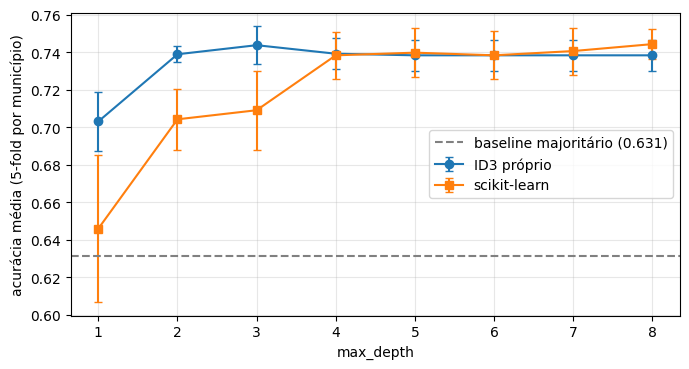

In [ ]:
fig, ax = plt.subplots(figsize=(7, 3.8))
ax.errorbar(sweep.index, sweep.ID3_cv, sweep.ID3_std, marker='o', label='ID3 próprio', capsize=3)
ax.errorbar(sweep.index, sweep.SK_cv, sweep.SK_std, marker='s', label='scikit-learn', capsize=3)
ax.axhline(base, ls='--', c='gray', label=f'baseline majoritário ({base:.3f})')
ax.set_xlabel('max_depth'); ax.set_ylabel('acurácia média (5-fold por município)'); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

In [ ]:
prof = lambda m: m.profundidade() if isinstance(m, ID3) else m.get_depth()
linhas = {}
for nome, mk, dados, d in [('Implementação própria', lambda d: ID3(max_depth=d), X, d_id3),
                           ('Scikit-learn', sk, Xoh, d_sk)]:
    full, podada = mk(None).fit(dados, y), mk(d).fit(dados, y)
    linhas[nome] = {
        'Acurácia de treinamento (sem poda)': full.score(dados, y),
        'Acurácia de treinamento (podada)': podada.score(dados, y),
        'Acurácia média 5-fold (sem poda)': cv_acc(lambda: mk(None), folds_g, dados)[0],
        'Acurácia média 5-fold (podada)': cv_acc(lambda: mk(d), folds_g, dados)[0],
        'Profundidade (sem poda)': prof(full),
        'Profundidade (podada)': prof(podada),
        'max_depth escolhido': d,
        'Memo: 5-fold simples, podada (com vazamento)': cv_acc(lambda: mk(d), folds_s, dados)[0],
    }
tabela = pd.DataFrame(linhas)
tabela.loc['Memo: baseline majoritário, 5-fold'] = [base] * 2
tabela.round(4)

,Implementação própria,Scikit-learn
Acurácia de treinamento (sem poda),0.7758,0.7758
Acurácia de treinamento (podada),0.7553,0.7403
Acurácia média 5-fold (sem poda),0.7383,0.7369
Acurácia média 5-fold (podada),0.7388,0.7383
Profundidade (sem poda),5.0000,30.0000
Profundidade (podada),2.0000,4.0000
max_depth escolhido,2.0000,4.0000
"Memo: 5-fold simples, podada (com vazamento)",0.7391,0.7386
"Memo: baseline majoritário, 5-fold",0.6311,0.6311


### Leitura dos resultados
- O ganho real do modelo é medido contra o **baseline majoritário** (~63%): a árvore chega a ~74% na validação, cerca de 11 pontos acima.
- A diferença treino × validação é pequena (poucos pontos). Com 5 atributos categóricos grosseiros, muitos municípios têm **exatamente os mesmos valores de atributos e rótulos diferentes**, o que impõe um teto de acurácia de treino (~78%) mesmo sem poda.
- As acurácias de validação das profundidades 2 a 8 diferem menos que o desvio entre folds: **não há ganho confiável além de profundidade ~2–4**. A árvore sem poda do scikit-learn chega a profundidade 30 só por testar colunas *one-hot* de `CO_UF` uma a uma, sem ganho de desempenho.

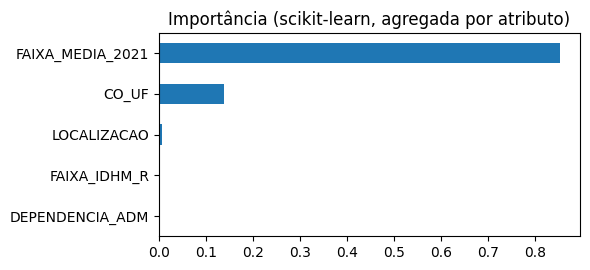

In [ ]:
# Importância dos atributos no scikit-learn (agregada por atributo original)
arv = sk(d_sk).fit(Xoh, y)
imp = pd.Series(arv.feature_importances_, index=Xoh.columns)
imp = imp.groupby(lambda c: next(a_ for a_ in ATTRS if c.startswith(a_ + '_'))).sum().sort_values()
imp.plot.barh(figsize=(6, 2.8), title='Importância (scikit-learn, agregada por atributo)'); plt.tight_layout(); plt.show()

## 7. Monotonicidade: um exemplo novo pode invalidar conclusões anteriores
A lógica clássica é **monotônica**: acrescentar premissas nunca derruba conclusões já obtidas. O aprendizado indutivo **não é**: a árvore depende da distribuição dos exemplos, e dados novos podem trocar o atributo da raiz e as regras abaixo dele. Demonstração empírica abaixo, com subconjuntos **aninhados** (cada um contém o anterior).

In [ ]:
rng = np.random.RandomState(SEED)
ordem = rng.permutation(len(df))
Xr, yr = X.reset_index(drop=True), y

linhas, ant = [], None
for n in [25, 40, 60, 100, 200, 500, 1000, len(df)]:
    idx = ordem[:n]; t = ID3(max_depth=3).fit(Xr.iloc[idx], yr[idx])
    pred = t.predict(Xr)            # predição para o conjunto todo
    mudou = np.nan if ant is None else (pred != ant).mean()
    linhas.append(dict(n_treino=n, raiz=t.raiz_.attr, IG_raiz=t._ganho(Xr.iloc[idx], yr[idx], t.raiz_.attr),
                       n_folhas=t.n_folhas(), pct_predicoes_que_mudaram=mudou)); ant = pred
pd.DataFrame(linhas).round(3)

,n_treino,raiz,IG_raiz,n_folhas,pct_predicoes_que_mudaram
0,25,CO_UF,0.570,13,NaN
1,40,CO_UF,0.386,27,0.132
2,60,CO_UF,0.380,38,0.073
3,100,CO_UF,0.299,50,0.141
4,200,CO_UF,0.231,72,0.201
5,500,FAIXA_MEDIA_2021,0.182,115,0.152
6,1000,FAIXA_MEDIA_2021,0.176,146,0.083
7,3519,FAIXA_MEDIA_2021,0.169,206,0.121


In [ ]:
# Estabilidade da raiz: 300 reamostragens (bootstrap) de 60 exemplos
cont = Counter()
for _ in range(300):
    idx = rng.choice(len(df), 60, replace=True)
    cont[ID3(max_depth=1).fit(Xr.iloc[idx], yr[idx]).raiz_.attr] += 1
print('Atributo escolhido como raiz em 300 amostras de 60 exemplos:'); print(pd.Series(cont).sort_values(ascending=False).to_string())

# Um caso concreto: o que muda quando chegam novos exemplos (40 → 200 → todos)
def top_gains(idx, k=3):
    g = pd.Series({a_: ID3()._ganho(Xr.iloc[idx], yr[idx], a_) for a_ in ATTRS}).sort_values(ascending=False)
    return ', '.join(f'{n}={v:.3f}' for n, v in g.head(k).items())
for n in [40, 200, len(df)]:
    print(f'n={n:>5}: ganhos (3 maiores) → {top_gains(ordem[:n])}')

t1 = ID3(max_depth=2).fit(Xr.iloc[ordem[:40]], yr[ordem[:40]]); t2 = ID3(max_depth=2).fit(Xr.iloc[ordem[:200]], yr[ordem[:200]])
p1, p2 = t1.predict(Xr), t2.predict(Xr); dif = p1 != p2
print(f'\n{dif.mean():.1%} dos municípios mudam de classificação entre a árvore de 40 e a de 200 exemplos. Exemplos:')
print(df.loc[dif, ATTRS + [TARGET]].assign(pred_40=p1[dif], pred_200=p2[dif]).head(8).to_string())

Atributo escolhido como raiz em 300 amostras de 60 exemplos:
CO_UF               250
FAIXA_MEDIA_2021     50
n=   40: ganhos (3 maiores) → CO_UF=0.386, FAIXA_MEDIA_2021=0.167, FAIXA_IDHM_R=0.037
n=  200: ganhos (3 maiores) → CO_UF=0.231, FAIXA_MEDIA_2021=0.230, FAIXA_IDHM_R=0.088
n= 3519: ganhos (3 maiores) → FAIXA_MEDIA_2021=0.169, CO_UF=0.100, FAIXA_IDHM_R=0.061

24.1% dos municípios mudam de classificação entre a árvore de 40 e a de 200 exemplos. Exemplos:
  CO_UF DEPENDENCIA_ADM LOCALIZACAO FAIXA_MEDIA_2021 FAIXA_IDHM_R  ALVO_MELHORA  pred_40  pred_200
0    11        Estadual      Urbana          250-265        medio             1        1         0
3    11        Estadual      Urbana          265-280        medio             1        1         0
4    11        Estadual       Rural            >=280        medio             0        1         0
5    11        Estadual      Urbana          265-280        medio             0        1         0
6    11        Estadual       Rural      

**Conclusão da seção:** a raiz e as regras abaixo dela variam com o conjunto de treino, e a classificação de parte dos municípios muda quando chegam novos exemplos. Logo, as regras aprendidas **não são conclusões permanentes**: a árvore deve ser reconstruída e reavaliada quando novos dados (por exemplo, o SAEB 2025) forem incorporados, e a estabilidade do modelo deve ser verificada.

## 8. Limitações e pontos para o relatório
1. **Regressão à média / efeito-teto:** `FAIXA_MEDIA_2021` domina a árvore. Quem partiu de nota baixa tem mais "espaço" para subir. A regra não prova efeito do Novo Ensino Médio.
2. **Confusores de 2021:** o SAEB 2021 foi aplicado durante a pandemia (participação e condições atípicas), o que afeta a comparação 2021→2023 independentemente de reformas.
3. **Alvo binário descarta magnitude:** subir 0,1 ponto e subir 20 pontos viram a mesma classe. Para a Etapa 2, `MEDIA_12_MT_2023 − MEDIA_12_MT_2021` serve de alvo contínuo.
4. **Censo de 2010** tem 13 anos de defasagem; `IDHM_R` é um retrato antigo da renda municipal.
5. **Unidade de análise:** linhas de um mesmo município não são independentes. A validação por grupos mitiga o problema, mas a amostra efetiva é de ~3 mil municípios, não 3,5 mil linhas.
6. **SAEB 2025:** citado no relatório como análise complementar, mas o arquivo não foi fornecido; esta etapa usa apenas 2021 e 2023.
7. **`CO_UF` é de alta cardinalidade** e favorece o ganho de informação puro; considerar razão de ganho ou agrupar por região.

## 9. Exportar a tabela de métricas para o LaTeX

In [ ]:
lat = tabela.copy(); lat.index = [i.replace('%', r'\%').replace('_', r'\_') for i in lat.index]
print(lat.round(3).to_latex(float_format='%.3f', caption='Métricas de avaliação dos classificadores.', label='tab:metricas'))

\begin{table}
\caption{Métricas de avaliação dos classificadores.}
\label{tab:metricas}
\begin{tabular}{lrr}
\toprule
 & Implementação própria & Scikit-learn \\
\midrule
Acurácia de treinamento (sem poda) & 0.776 & 0.776 \\
Acurácia de treinamento (podada) & 0.755 & 0.740 \\
Acurácia média 5-fold (sem poda) & 0.738 & 0.737 \\
Acurácia média 5-fold (podada) & 0.739 & 0.738 \\
Profundidade (sem poda) & 5.000 & 30.000 \\
Profundidade (podada) & 2.000 & 4.000 \\
max\_depth escolhido & 2.000 & 4.000 \\
Memo: 5-fold simples, podada (com vazamento) & 0.739 & 0.739 \\
Memo: baseline majoritário, 5-fold & 0.631 & 0.631 \\
\bottomrule
\end{tabular}
\end{table}

